In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio

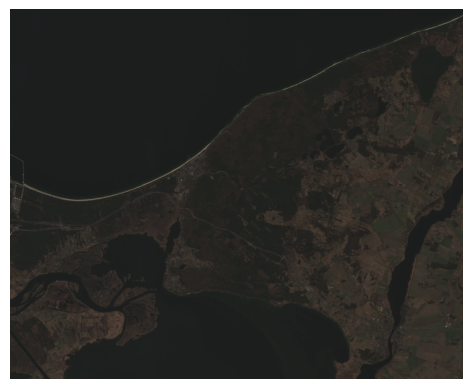

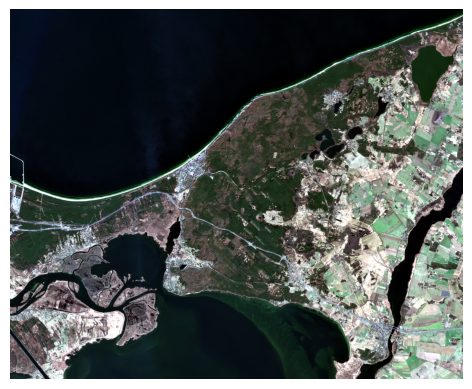

In [ ]:
#Wyświetl raster w kolorach możliwie odzwierciedlających rzeczywistość

path_to_files = "C:/Users/julia/Desktop/SDG/cwiczenia/dane/raster/sentinel/"

path = path_to_files + "sentinel-2-l2a_2026-03-18_S2C_MSIL2A_20260318T100741_R022_T33UVV_20260318T161111_"

with rasterio.open(path + "B04.tif") as src:
    red = src.read(1)

with rasterio.open(path + "B03.tif") as src:
    green = src.read(1)

with rasterio.open(path + "B02.tif") as src:
    blue = src.read(1)

rgb_stacked = np.stack([red, green, blue])

raster_rgb = np.moveaxis(rgb_stacked, 0, -1)

# Normalizacja danych:
raster_rgb2 = raster_rgb.astype(float).copy()
for i in range(3):
    low = np.percentile(raster_rgb2[:, :, i], 2)
    high = np.percentile(raster_rgb2[:, :, i], 98)

    raster_rgb2[:, :, i] = np.clip(
        (raster_rgb2[:, :, i] - low) / (high - low),
        0,
        1
    )

plt.imshow(raster_rgb2)
plt.axis("off")
plt.show()

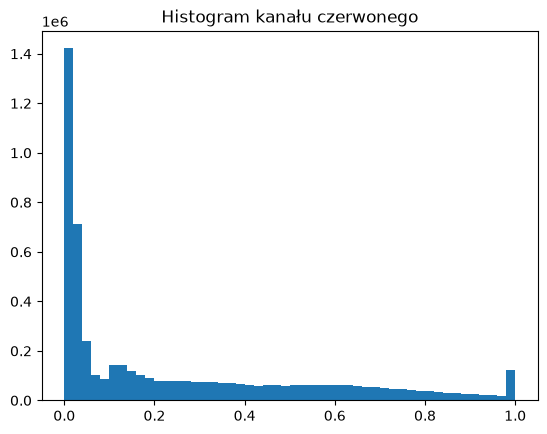

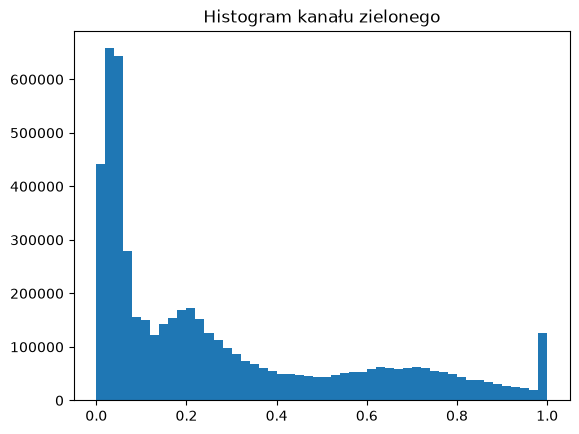

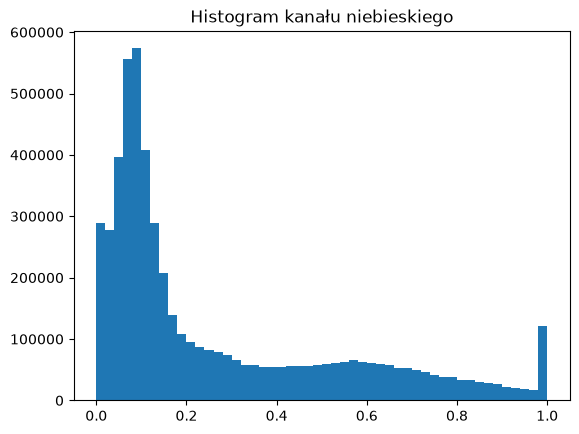

In [9]:
# Przedstaw i krótko opisz histogram wartości dla każdego kanału

plt.hist(raster_rgb2[:, :, 0].flatten(), bins=50)
plt.title("Histogram kanału czerwonego")
plt.show()

plt.hist(raster_rgb2[:, :, 1].flatten(), bins=50)
plt.title("Histogram kanału zielonego")
plt.show()

plt.hist(raster_rgb2[:, :, 2].flatten(), bins=50)
plt.title("Histogram kanału niebieskiego")
plt.show()

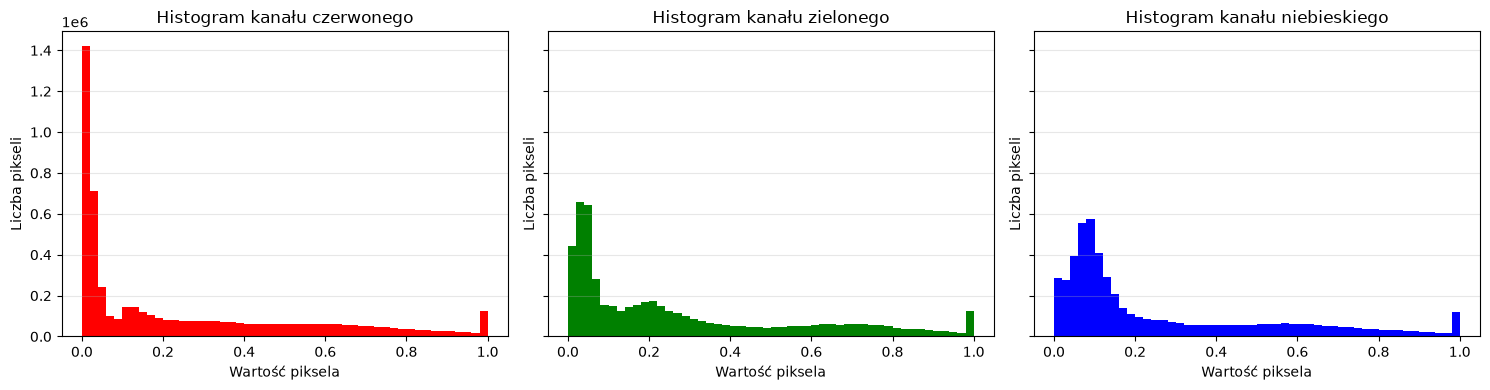

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

kanaly = [
    (0, "czerwonego", "red"),
    (1, "zielonego", "green"),
    (2, "niebieskiego", "blue"),
]

for ax, (indeks, nazwa, kolor) in zip(axes, kanaly):
    ax.hist(raster_rgb2[:, :, indeks].ravel(), bins=50, color=kolor)
    ax.set_title(f"Histogram kanału {nazwa}")
    ax.set_xlabel("Wartość piksela")
    ax.set_ylabel("Liczba pikseli")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

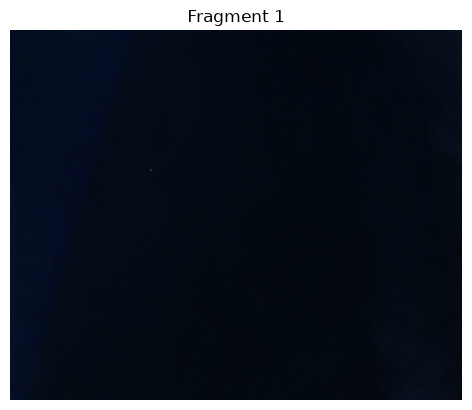

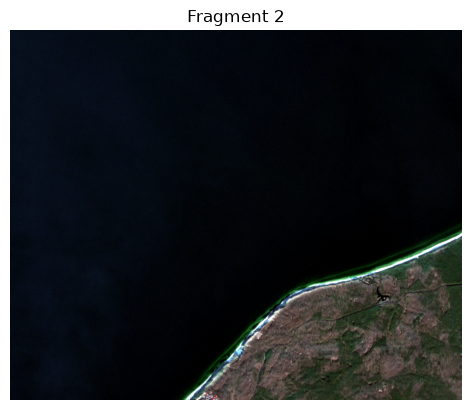

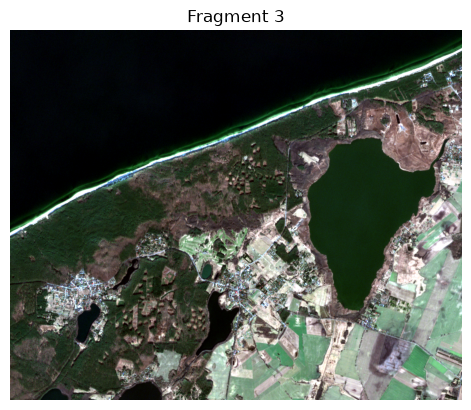

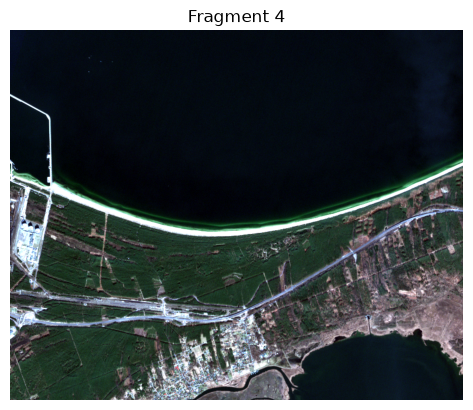

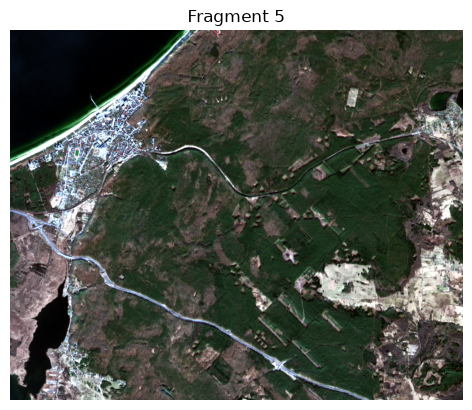

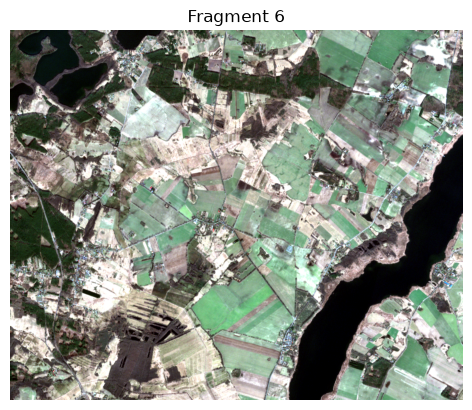

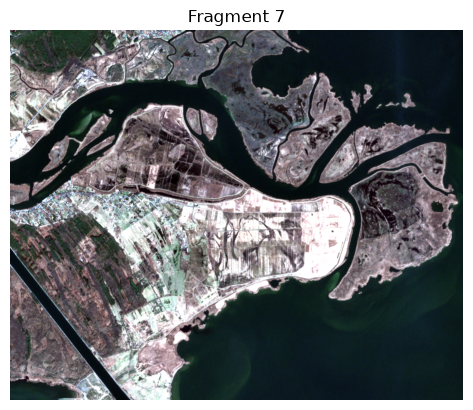

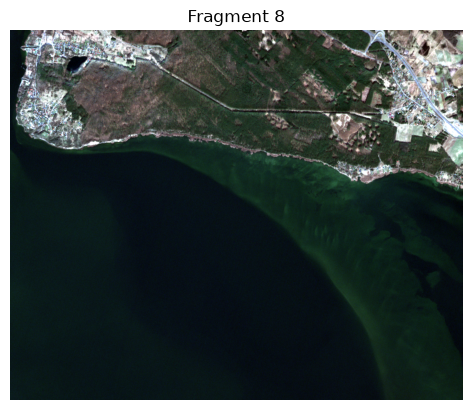

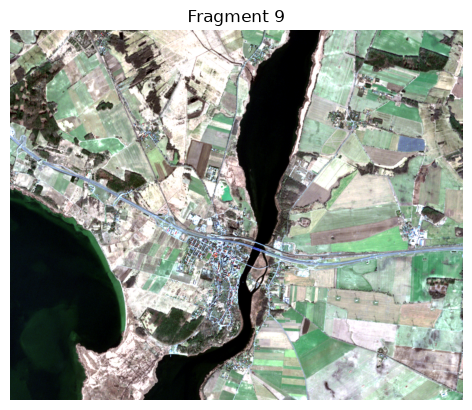

In [ ]:
rows = np.array_split(raster_rgb2, 3, axis=0)

parts = [np.array_split(r, 3, axis=1) for r in rows]


In [ ]:
# Zapisz raster do 1 pliku RGB złożonego z zaciągniętych 3 kanałów
combined_raster = np.stack([raster_rgb2[:, :, 0], raster_rgb2[:, :, 1], raster_rgb2[:, :, 2]], axis=2)


c:\Users\julia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\rasterio\__init__.py:389: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(
